In [24]:
from config import *
import numpy as np
import matplotlib.pyplot as plt
from astropy.table import Table

## Load in Pair Data and Control Data

In [25]:
parent = Table.read('out/parent.fits', unit_parse_strict = 'silent')
pairs = Table.read('out/pairs.fits', unit_parse_strict = 'silent')

in_sample = np.asarray(parent['in_sample'])

# Get the indices of the primary galaxies and their matched controls
ctrl_indices = np.asarray(pairs['control_index'])
matched = ctrl_indices[:, 0] != -1
p = np.asarray(pairs['primary_index'])[matched]
c = ctrl_indices[matched]

# Extract data for SFR calculation
z = np.asarray(parent['Z'], dtype = float)
logM = np.asarray(parent['logmstar'], dtype = float)
sigma_logM = np.asarray(parent['dellogmstar'], dtype = float)
M_r = np.asarray(parent['absmag_r'], dtype = float)
sigma_M_r = np.asarray(parent['delabsmag_r'], dtype = float)
F_HA = np.asarray(parent['HA_FLUX'], dtype = float)
sigma_F_HA = np.asarray(parent['HA_FLUX_ERR'], dtype = float)
EW_HA = np.asarray(parent['HA_EW'], dtype = float)
sigma_EW_HA = np.asarray(parent['HA_EW_ERR'], dtype = float)
F_HB = np.asarray(parent['HB_FLUX'], dtype = float)
sigma_F_HB = np.asarray(parent['HB_FLUX_ERR'], dtype = float)

## Calculate SFRs

The $\text{H}\alpha$ luminosity is given by
$$ L_{\text{H}\alpha} = (\text{EW}_{\text{H}\alpha} + \text{EW}_c) \times 10^{-0.4 (M_r - 34.1)} \times \frac{3 \times 10^{18}}{[6564.1(1 + z)]^2} \bigg( \frac{F_{\text{H}\alpha} / F_{\text{H}\beta}}{2.86} \bigg)^{2.36} $$
The SFR is given by
$$ \text{SFR}_{\text{H}\alpha} \, (M_\odot \, \text{yr}^{-1}) = \frac{L_{\text{H}\alpha} \, (\text{W\,Hz}^{-1})}{1.27 \times 10^{34}} $$
(Davies et al. 2015)
The sSFR enhancement is given by
$$ \Delta \log(\text{sSFR}) = \log(\text{sSFR}_\text{pair}) - \langle \log(\text{sSFR}_\text{ctrl}) \rangle _\text{med} $$
(Puskas et al. 2025)

In [26]:
with np.errstate(divide = 'ignore', invalid = 'ignore'):
    # Calculate the Balmer decrement, using the median for galaxies without valid measurements
    valid_BD = np.all([(F > 0) & (sigma > 0) & (F / sigma >= SN_MIN) for F, sigma in [(F_HA, sigma_F_HA), (F_HB, sigma_F_HB)]], axis = 0)
    BD_measured = np.clip(F_HA / F_HB, 2.86, None)
    BD_median = np.median(BD_measured[in_sample & valid_BD])
    BD = np.where(valid_BD, BD_measured, BD_median)

    # Calculate the H-alpha luminosity
    L_HA = np.clip(EW_HA + EW_C, 0.1, None) * 10 ** (-0.4 * (M_r - 34.1)) * 3e18 / (LAMBDA_HA * (1 + z)) ** 2 * (BD / 2.86) ** 2.36

    # Calculate the SFR and sSFR
    SFR = L_HA / 1.27e34
    log_SFR = np.log10(SFR)
    log_sSFR = log_SFR - logM

print(f'Median Balmer decrement used for undetected galaxies: {BD_median:.2f}')
print(f'Sample galaxies with a measured Balmer decrement: {np.sum(in_sample & valid_BD)} of {np.sum(in_sample)}')

# Calculate the sSFR enhancement for the primary galaxies and their matched controls
Delta_log_sSFR = log_sSFR[p] - np.median(log_sSFR[c], axis = 1)

Median Balmer decrement used for undetected galaxies: 4.55
Sample galaxies with a measured Balmer decrement: 24014 of 42214


## Calculate Uncertainties

Taking the log of the $\text{H}\alpha$ luminosity
$$ \log L_{\text{H}\alpha} = \log(\text{EW} + \text{EW}_c) - 0.4(M_r - 34.10) + \log \bigg( \frac{3 \times 10^{18}}{[6564.1(1 + z)]^2} \bigg) + 2.36 \log \bigg( \frac{F_{\text{H}\alpha} / F_{\text{H}\beta}}{2.86} \bigg) $$
The uncertainty in the $\text{H}\alpha$ luminosity is given by
$$ \sigma_{\log L} = \sqrt{\bigg( \frac{\sigma_{\text{EW}_{\text{H}\alpha}}}{(\text{EW}_{\text{H}\alpha} + \text{EW}_c) \ln 10} \bigg)^2 + \bigg( 0.4 \sigma_{M_r} \bigg)^2 + \bigg( 2.36 \sigma_{\log BD} \bigg)^2} $$
The EW term is capped at 0.5 dex, since it diverges as $\text{EW}_{\text{H}\alpha} + \text{EW}_c \to 0$.

The uncertainty in the Balmer decrement is given by
$$ \sigma_{\log BD} = \frac{1}{\ln 10} \sqrt{\bigg( \frac{\sigma_{F_{\text{H}\alpha}}}{F_{\text{H}\alpha}} \bigg)^2 + \bigg( \frac{\sigma_{F_{\text{H}\beta}}}{F_{\text{H}\beta}} \bigg)^2} $$
The uncertainty in the $\text{H}\alpha$ SFR is given by
$$ \sigma_{\log\text{SFR}} = \sigma_{\log L} $$
The uncertainty in the sSFR is given by
$$ \sigma_{\log\text{sSFR}} = \sqrt{\sigma_{\log\text{SFR}}^2 + \sigma_{\log M_\star}^2} $$
The uncertainty in the sSFR enhancement is given by
$$ \sigma_{\Delta \log\text{sSFR}} = \sqrt{\sigma_\text{pair}^2 + \sigma_\text{med}^2} $$
$$ \sigma_\text{med} = 1.253 \frac{\sqrt{\langle \sigma_\text{ctrl}^2 \rangle}}{\sqrt{5}} $$

In [27]:
# Calculate the uncertainty in the sSFR
with np.errstate(divide = 'ignore', invalid = 'ignore'):
    sigma_log_BD = np.sqrt((sigma_F_HA / F_HA) ** 2 + (sigma_F_HB / F_HB) ** 2) * (1 / np.log(10))
    sigma_log_BD = np.where(F_HA / F_HB < 2.86, 0.0, sigma_log_BD)

    # Galaxies using the median Balmer decrement get the scatter of the measured decrements as their uncertainty
    sigma_log_BD = np.where(valid_BD, sigma_log_BD, np.std(np.log10(BD_measured[in_sample & valid_BD])))

    # The log error on the EW blows up as EW + EW_C approaches zero, so cap it at SIGMA_LOG_EW_MAX dex
    SIGMA_LOG_EW_MAX = 0.5
    sigma_log_EW = np.minimum(np.abs(sigma_EW_HA / (np.clip(EW_HA + EW_C, 0.1, None) * np.log(10))), SIGMA_LOG_EW_MAX)

    sigma_log_SFR = np.sqrt(sigma_log_EW ** 2 + (0.4 * sigma_M_r) ** 2 + (2.36 * sigma_log_BD) ** 2)

sigma_log_sSFR = np.sqrt(sigma_log_SFR ** 2 + sigma_logM ** 2)

# Calculate the uncertainty in the sSFR enhancement
sigma_pair = sigma_log_sSFR[p]
sigma_med = 1.253 * np.sqrt(np.mean(sigma_log_sSFR[c] ** 2, axis = 1)) / np.sqrt(N_CTRL)
sigma_Delta_log_sSFR = np.sqrt(sigma_pair ** 2 + sigma_med ** 2)

## Save Data to File

In [28]:
sfr_halpha = Table({'primary_index': p, 'control_index': c, 'rp': np.asarray(pairs['rp'])[matched],
                    'Delta_log_sSFR': Delta_log_sSFR, 'sigma_Delta_log_sSFR': sigma_Delta_log_sSFR,
                    'log_sSFR_primary': log_sSFR[p], 'log_sSFR_controls': log_sSFR[c],
                    'sigma_log_sSFR': sigma_log_sSFR[p], 'sigma_log_sSFR_controls': sigma_log_sSFR[c]})
sfr_halpha.write('out/sfr_halpha.fits', overwrite = True)

## Diagnostic Plots

In [29]:
# Global plot style
plt.rcParams.update({
    'axes.linewidth': 2.0,
    'axes.labelsize': 14,
    'axes.labelweight': 'normal',
    'xtick.major.width': 2.0,
    'ytick.major.width': 2.0,
    'xtick.minor.width': 1.5,
    'ytick.minor.width': 1.5,
    'xtick.major.size': 6,
    'ytick.major.size': 6,
    'xtick.minor.size': 4,
    'ytick.minor.size': 4,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12})

# Method to bold the tick labels
def bold_ticks(*axes):
    for ax in axes:
        labels = (ax.get_xticklabels() + ax.get_yticklabels()
            + ax.get_xticklabels(minor = True) + ax.get_yticklabels(minor = True))

        for label in labels:
            label.set_fontweight('bold')

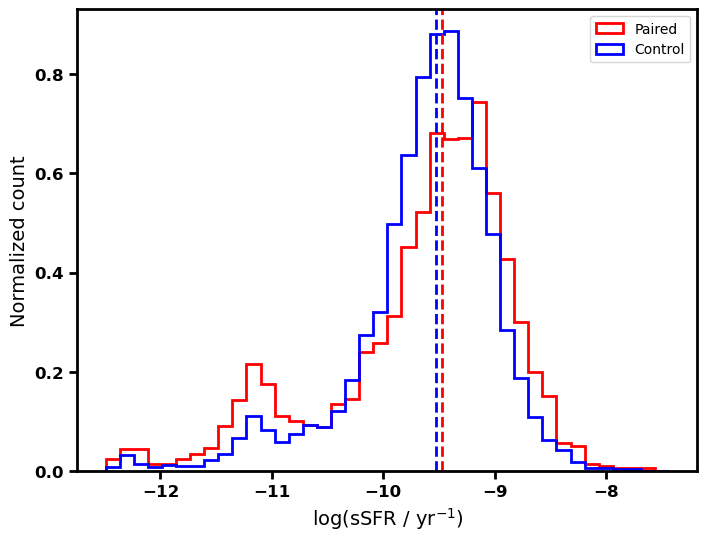

In [30]:
# Plot the log sSFR distributions of the paired and control galaxies
fig, ax = plt.subplots(figsize = (8, 6))

log_sSFR_pair = log_sSFR[p]
log_sSFR_ctrl = log_sSFR[c].ravel()

bins = np.histogram_bin_edges(np.concatenate([log_sSFR_pair, log_sSFR_ctrl]), bins = 40)
ax.hist(log_sSFR_pair, bins = bins, density = True, histtype = 'step', linewidth = 2, color = 'red', label = 'Paired')
ax.hist(log_sSFR_ctrl, bins = bins, density = True, histtype = 'step', linewidth = 2, color = 'blue', label = 'Control')

# Median of each distribution
ax.axvline(np.median(log_sSFR_pair), color = 'red', linestyle = '--', linewidth = 2)
ax.axvline(np.median(log_sSFR_ctrl), color = 'blue', linestyle = '--', linewidth = 2)

ax.set_xlabel(r'log(sSFR / yr$^{-1}$)')
ax.set_ylabel('Normalized count')
ax.legend()

bold_ticks(ax)

plt.savefig("figs/halpha_sfr_distribution.pdf", format = "pdf", bbox_inches = "tight")
plt.savefig("figs/halpha_sfr_distribution.png", format = "png", bbox_inches = "tight")

plt.show()